In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# testing for ctable = 1.5 and ptable =0.7.. this is from talys

df_p=pd.read_table("testing_p.txt",delimiter=r"\s+")
df_p['ld_eff']=df_p['JP=0.0']+df_p['JP=1.0']+df_p['JP=2.0']+df_p['JP=3.0']


df_n=pd.read_table("testing_n.txt",delimiter=r"\s+")
df_n['ld_eff']=df_n['JP=0.0']+df_n['JP=1.0']+df_n['JP=2.0']+df_n['JP=3.0']


df = df_p.set_index('Ex').add(df_n.set_index('Ex'), fill_value=0).reset_index()

df_p

,Ex,total,JP=0.0,JP=1.0,JP=2.0,JP=3.0,JP=4.0,JP=5.0,JP=6.0,JP=7.0,JP=8.0,ld_eff
0,0.25,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,4.000000e-30
1,0.50,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,1.000000e-30,4.000000e-30
2,0.75,6.797000e-01,2.797000e-01,1.000000e-30,1.337000e-01,1.000000e-30,1.337000e-01,1.000000e-30,1.337000e-01,1.000000e-30,1.000000e-30,4.134000e-01
3,1.00,4.855000e+00,1.819000e+00,1.000000e-30,8.696000e-01,1.000000e-30,1.087000e+00,1.000000e-30,1.087000e+00,1.000000e-30,1.000000e-30,2.688600e+00
4,1.25,5.287000e+00,9.004000e-01,1.000000e-30,1.192000e+00,2.908000e-01,1.163000e+00,1.000000e-30,1.454000e+00,1.000000e-30,2.908000e-01,2.383200e+00
5,1.50,1.990000e+01,5.661000e+00,1.000000e-30,7.498000e+00,1.829000e+00,1.094000e+00,3.657000e-01,1.829000e+00,1.000000e-30,1.829000e+00,1.498800e+01
6,1.75,3.390000e+01,6.883000e+00,9.302000e-01,9.516000e+00,2.674000e+00,7.395000e+00,2.223000e+00,2.223000e+00,1.000000e-30,2.223000e+00,2.000320e+01
7,2.00,5.949000e+01,8.185000e+00,6.061000e+00,1.478000e+01,6.384000e+00,1.393000e+01,3.171000e+00,4.227000e+00,5.287000e-01,2.644000e+00,3.541000e+01
8,2.25,1.075000e+02,8.285000e+00,1.013000e+01,2.459000e+01,1.347000e+01,2.126000e+01,7.417000e+00,1.236000e+01,3.711000e+00,2.475000e+00,5.647500e+01
9,2.50,1.719000e+02,1.017000e+01,1.684000e+01,3.215000e+01,2.650000e+01,4.253000e+01,1.598000e+01,1.598000e+01,7.287000e+00,3.636000e+00,8.566000e+01


In [5]:
# contruct from the database
# just to see that construction works , nothing else
# construct
# this is only used for pulling down values
df_p =pd.read_pickle("master_ld_data_base/master_base_ld_p.pkl")
df_n = pd.read_pickle("master_ld_data_base/master_base_ld_n.pkl")


df_base_p =pd.read_pickle("master_ld_data_base/base_ld_p.pkl") # run talys for p=0, c=0  and store it as base_ld_p.pkl and likewised for negative
df_base_n = pd.read_pickle("master_ld_data_base/base_ld_n.pkl")

# fresh can be used for anything
df_param_p = df_base_p.copy()
df_param_n = df_base_n.copy()


ctable = 
ptable = 0.7

new_energy = df_base_p['Ex'].values - ptable

# for postive_ld
for col in df_base_p.columns[1:]:
    shifted_values = np.interp(new_energy, df_p['Ex'].values, df_p[col].values)
    new_values = np.exp(ctable* np.sqrt(np.abs(new_energy)))* shifted_values
    df_base_p[col] = new_values

new_energy = df_base_n['Ex'].values - ptable

# for negative_ld
for col in df_base_n.columns[1:]:
    shifted_values = np.interp(new_energy, df_n['Ex'].values, df_n[col].values)
    new_values = np.exp(ctable* np.sqrt(np.abs(new_energy)))* shifted_values
    df_base_n[col] = new_values


df_final= df_base_p.set_index('Ex').add(df_base_n.set_index('Ex'), fill_value=0).reset_index()

df_final['ld_eff']=df_final['JP=0.0']+df_final['JP=1.0']+df_final['JP=2.0']+df_final['JP=3.0'] # change this for your nuclei



df_final

,Ex,total,JP=0.0,JP=1.0,JP=2.0,JP=3.0,JP=4.0,JP=5.0,JP=6.0,JP=7.0,JP=8.0,ld_eff
0,0.25,5.470542e-30,5.470542e-30,5.470542e-30,5.470542e-30,5.470542e-30,5.470542e-30,5.470542e-30,5.470542e-30,5.470542e-30,5.470542e-30,2.188217e-29
1,0.50,3.911682e-30,3.911682e-30,3.911682e-30,3.911682e-30,3.911682e-30,3.911682e-30,3.911682e-30,3.911682e-30,3.911682e-30,3.911682e-30,1.564673e-29
2,0.75,6.796778e-01,2.797028e-01,2.797028e-30,1.336979e-01,2.797028e-30,1.336979e-01,2.797028e-30,1.336979e-01,2.797028e-30,2.797028e-30,4.134007e-01
3,1.00,4.855201e+00,1.819279e+00,4.548198e-30,8.696154e-01,4.548198e-30,1.087019e+00,4.548198e-30,1.087019e+00,4.548198e-30,4.548198e-30,2.688894e+00
4,1.25,6.521491e+00,9.003551e-01,6.083480e-30,1.192362e+00,3.015581e-01,1.771509e+00,6.083480e-30,1.461434e+00,6.083480e-01,2.907904e-01,2.394275e+00
5,1.50,2.854067e+01,5.661466e+00,7.650630e-30,7.497617e+00,1.896209e+00,4.919355e+00,7.314002e-01,2.240869e+00,3.825315e+00,2.194201e+00,1.505529e+01
6,1.75,5.284257e+01,6.883207e+00,9.301631e-01,9.532498e+00,3.200691e+00,1.293857e+01,4.889868e+00,4.945677e+00,5.543772e+00,5.378203e+00,2.054656e+01
7,2.00,1.106028e+02,8.185016e+00,7.117646e+00,1.593977e+01,1.181297e+01,2.530166e+01,1.003992e+01,1.173776e+01,1.184394e+01,1.130417e+01,4.305540e+01
8,2.25,2.284615e+02,8.284158e+00,1.631591e+01,3.089085e+01,3.240530e+01,3.733049e+01,2.395287e+01,3.235352e+01,1.996870e+01,1.620200e+01,8.789621e+01
9,2.50,3.514907e+02,1.016764e+01,2.406117e+01,4.236143e+01,5.058383e+01,6.274909e+01,4.338643e+01,4.685794e+01,3.057026e+01,2.614857e+01,1.271741e+02


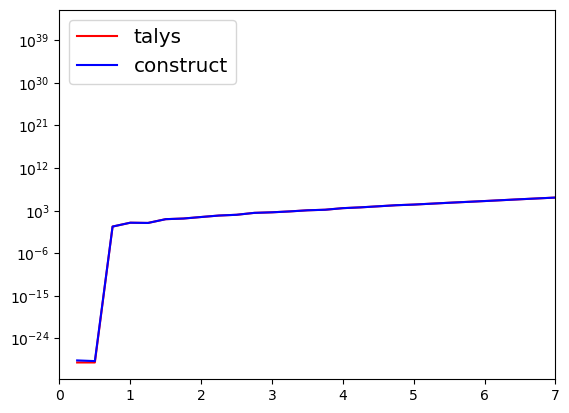

In [7]:


plt.plot(df['Ex'],df['ld_eff'], color='r', label= 'talys')
         
plt.plot(df_final['Ex'], df_final['ld_eff'],color='b', label = 'construct')

plt.yscale("log")

plt.xlim(0,7)
#plt.ylim(0.1,7000)

plt.legend(loc ='upper left',fontsize="x-large")
plt.show()


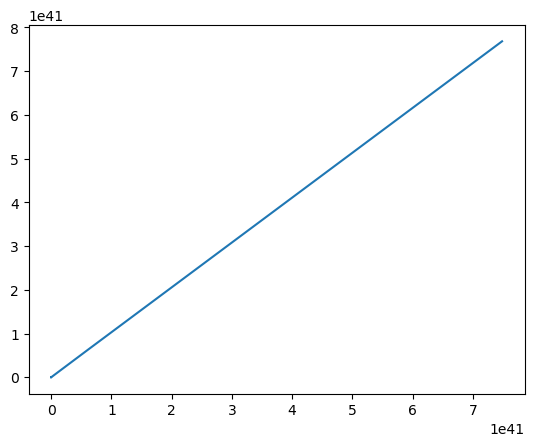